# Pair 1 - Synthetic student data generation

**Business need:** let analysts study student progression with **synthetic** records instead of real ones, so no real student can be identified.

| | System A | System B |
|---|---|---|
| Model | **CTGAN** | **ForestFlow** |
| How it works | A **GAN** for tables: a generator makes fake rows, a discriminator tries to spot them, and they compete (minimax) | **Flow matching** where small XGBoost tree models learn the velocity field; solving the ODE turns noise into rows |
| Lecture link | Week 9 (GANs) | Week 10 (flow matching, ODEs) |

**Real data:** UCI *Student Performance* (649 Portuguese secondary students, public and de-identified).
**Baseline:** resample each column on its own. It gets every column's distribution right but destroys the links between columns. Any real model should beat it.

In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors

os.makedirs("outputs/p1", exist_ok=True)
os.makedirs("results/p1", exist_ok=True)

In [2]:
# Download the dataset once and keep a local copy
if not os.path.exists("data/p1_student_por.csv"):
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=320)
    pd.concat([d.data.features, d.data.targets], axis=1).to_csv("data/p1_student_por.csv", index=False)

students = pd.read_csv("data/p1_student_por.csv")

CATEGORICAL = ["school", "sex", "address", "famsize", "schoolsup", "internet", "higher", "romantic"]
NUMERIC = ["age", "Medu", "studytime", "failures", "goout", "health", "absences", "G1"]
students["passed"] = np.where(students["G3"] >= 10, "yes", "no")       # final grade 10+ out of 20 = pass
students = students[CATEGORICAL + NUMERIC + ["passed"]]
students.head()

,school,sex,address,famsize,schoolsup,internet,higher,romantic,age,Medu,studytime,failures,goout,health,absences,G1,passed
0,GP,F,U,GT3,yes,no,yes,no,18,4,2,0,4,3,4,0,yes
1,GP,F,U,GT3,no,yes,yes,no,17,1,2,0,3,3,2,9,yes
2,GP,F,U,LE3,yes,yes,yes,no,15,1,2,0,2,3,6,12,yes
3,GP,F,U,GT3,no,yes,yes,yes,15,4,3,0,2,5,0,14,yes
4,GP,F,U,GT3,no,no,yes,no,16,3,2,0,2,5,0,11,yes


In [3]:
# Everything is repeated with 3 different random splits (seeds 0, 1, 2): 
# 70% of students to train the generators, 30% kept aside as "unseen real students" for testing.

SEEDS = [0, 1, 2]
splits = {}
for seed in SEEDS:
    train, test = train_test_split(students, test_size=0.3, random_state=seed, stratify=students["passed"])
    splits[seed] = (train, test)
times_log = []

## System A: CTGAN

In [4]:
from ctgan import CTGAN

for seed in SEEDS:
    train, test = splits[seed]
    start = time.time()
    model = CTGAN(epochs=300, enable_gpu=False)       # small tables train much faster on the CPU than on the Mac GPU
    model.set_random_state(seed)
    model.fit(train, discrete_columns=CATEGORICAL + ["passed"])
    synthetic = model.sample(len(train))
    times_log.append({"system": "A", "item": f"seed{seed}", "seconds": time.time() - start, "hand_minutes": 0})
    synthetic.to_csv(f"outputs/p1/A_seed{seed}.csv", index=False)

synthetic.head()

,school,sex,address,famsize,schoolsup,internet,higher,romantic,age,Medu,studytime,failures,goout,health,absences,G1,passed
0,GP,F,U,GT3,no,no,yes,no,16,2,1,1,2,3,1,15,yes
1,GP,M,U,GT3,no,yes,yes,no,19,1,2,0,3,4,8,8,yes
2,GP,F,U,GT3,no,no,yes,no,17,2,2,0,4,4,0,18,yes
3,GP,F,U,GT3,no,yes,yes,no,16,3,2,0,3,5,-1,12,yes
4,MS,F,R,GT3,no,yes,yes,no,17,2,2,0,4,4,1,15,yes


## System B: ForestFlow

**Why it runs as a separate Python process:** Since I’m running this on a Mac, ForestFlow needs to run in a separate process to avoid potential conflicts with CTGAN. The next cell saves the code to pair1B_forestflow.py, and the following cell runs it separately. The code itself remains the same as in the notebook.

In [5]:
%%writefile pair1B_forestflow.py
# Pair 1, System B: ForestFlow. Run as its own process by the next cell.
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from ForestDiffusion import ForestDiffusionModel

CATEGORICAL = ["school", "sex", "address", "famsize", "schoolsup", "internet", "higher", "romantic"]
NUMERIC = ["age", "Medu", "studytime", "failures", "goout", "health", "absences", "G1"]
ALL_CATEGORIES = CATEGORICAL + ["passed"]
columns = CATEGORICAL + NUMERIC + ["passed"]

students = pd.read_csv("data/p1_student_por.csv")
students["passed"] = np.where(students["G3"] >= 10, "yes", "no")
students = students[columns]

times = []
for seed in [0, 1, 2]:                                       
    train, test = train_test_split(students, test_size=0.3, random_state=seed, stratify=students["passed"])
    start = time.time()

    # categories -> number codes
    numbers = train.copy()
    categories = {}
    for col in ALL_CATEGORIES:
        categories[col] = sorted(train[col].unique())
        numbers[col] = train[col].map({value: i for i, value in enumerate(categories[col])})

    model = ForestDiffusionModel(numbers[columns].to_numpy(dtype=float), n_t=20, duplicate_K=20,
                                 diffusion_type="flow", n_jobs=1, seed=seed,
                                 cat_indexes=[columns.index(c) for c in ALL_CATEGORIES],
                                 int_indexes=[columns.index(c) for c in NUMERIC])
    synthetic = pd.DataFrame(model.generate(batch_size=len(train)), columns=columns)

    # number codes -> categories
    for col in ALL_CATEGORIES:
        codes = synthetic[col].round().astype(int).clip(0, len(categories[col]) - 1)
        synthetic[col] = [categories[col][code] for code in codes]

    synthetic.to_csv(f"outputs/p1/B_seed{seed}.csv", index=False)
    times.append({"system": "B", "item": f"seed{seed}", "seconds": time.time() - start, "hand_minutes": 0})
    print(f"seed {seed}: {time.time() - start:.0f}s")

pd.DataFrame(times).to_csv("results/p1/times_B.csv", index=False)

Overwriting pair1B_forestflow.py


In [6]:
import subprocess, sys

result = subprocess.run([sys.executable, "pair1B_forestflow.py"], capture_output=True, text=True)
print(result.stdout, result.stderr[-2000:] if result.returncode != 0 else "")

times_log += pd.read_csv("results/p1/times_B.csv").to_dict("records")
pd.DataFrame(times_log).to_csv("results/p1/times.csv", index=False)
pd.read_csv("outputs/p1/B_seed0.csv").head()

seed 0: 67s
seed 1: 67s
seed 2: 68s
 


,school,sex,address,famsize,schoolsup,internet,higher,romantic,age,Medu,studytime,failures,goout,health,absences,G1,passed
0,GP,F,U,LE3,no,yes,yes,yes,15.0,4.0,2.0,0.0,1.0,1.0,0.0,12.0,yes
1,MS,M,U,LE3,no,yes,no,no,17.0,1.0,1.0,2.0,5.0,4.0,4.0,7.0,no
2,GP,F,U,GT3,no,yes,yes,yes,17.0,4.0,2.0,0.0,4.0,5.0,3.0,11.0,yes
3,GP,M,U,LE3,no,yes,yes,yes,16.0,2.0,2.0,0.0,5.0,4.0,0.0,13.0,yes
4,GP,F,U,LE3,no,yes,yes,no,16.0,2.0,2.0,0.0,4.0,2.0,0.0,13.0,yes


## Metrics

- **fidelity**: Measures how similar each column is between real and synthetic data. The score ranges from 0 to 1, where 1 means they are identical.
- **corr_gap**: Measures how different the relationships between columns are in real and synthetic data. Lower is better.
- **tstr_auc** (Train on Synthetic, Test on Real): Train a model using synthetic student data and test it on real students it hasn’t seen before. The closer the result is to a model trained on real data, the more useful the synthetic data is.
- **too_close_rate** (privacy): Measures how many synthetic students are unusually similar to real training students. If no data is copied, the rate should be low. A higher rate may mean some synthetic students are too similar to real ones.


In [7]:
def to_numbers(table, reference):
    """One-hot encode categories and scale every column using the real training data, so distances are comparable."""
    X = pd.get_dummies(table[CATEGORICAL + NUMERIC], columns=CATEGORICAL, dtype=float)
    ref = pd.get_dummies(reference[CATEGORICAL + NUMERIC], columns=CATEGORICAL, dtype=float)
    X = X.reindex(columns=ref.columns, fill_value=0.0)
    return ((X - ref.mean()) / (ref.std() + 1e-9)).to_numpy()


def evaluate(synthetic, train, test):
    # 1. fidelity, column by column
    distances = [ks_2samp(train[c], synthetic[c]).statistic for c in NUMERIC]
    for c in CATEGORICAL:
        real_share = train[c].value_counts(normalize=True)
        synth_share = synthetic[c].value_counts(normalize=True)
        distances.append(0.5 * real_share.subtract(synth_share, fill_value=0).abs().sum())
    fidelity = 1 - np.mean(distances)

    # 2. relationships between numeric columns
    corr_gap = np.abs(train[NUMERIC].corr() - synthetic[NUMERIC].astype(float).corr()).to_numpy().mean()

    # 3. usefulness: train on synthetic, test on real
    classifier = LogisticRegression(max_iter=2000)
    classifier.fit(to_numbers(synthetic, train), synthetic["passed"] == "yes")
    tstr_auc = roc_auc_score(test["passed"] == "yes", classifier.predict_proba(to_numbers(test, train))[:, 1])

    # 4. privacy: how close each synthetic row is to its nearest real training student
    nearest = NearestNeighbors(n_neighbors=1).fit(to_numbers(train, train))
    synth_distance = nearest.kneighbors(to_numbers(synthetic, train))[0][:, 0]
    unseen_distance = nearest.kneighbors(to_numbers(test, train))[0][:, 0]
    too_close_rate = np.mean(synth_distance < np.percentile(unseen_distance, 5))

    return {"fidelity": fidelity, "corr_gap": corr_gap, "tstr_auc": tstr_auc, "too_close_rate": too_close_rate}

In [8]:
rows = []
for seed in SEEDS:
    train, test = splits[seed]
    # the baseline: shuffle each column on its own, with a different random order per column
    # (the same order for every column would just reorder whole rows, i.e. copy the real students)
    baseline = pd.DataFrame({c: train[c].sample(frac=1, random_state=seed * 100 + i).to_numpy()
                             for i, c in enumerate(train.columns)})
    tables = {"A": pd.read_csv(f"outputs/p1/A_seed{seed}.csv"),
              "B": pd.read_csv(f"outputs/p1/B_seed{seed}.csv"),
              "baseline": baseline}
    for name, table in tables.items():
        rows.append({"system": name, "seed": seed, **evaluate(table, train, test)})
    # reference: a model trained on the REAL training students (the best possible result)
    reference = evaluate(train, train, test)
    rows.append({"system": "real data", "seed": seed, **reference, "too_close_rate": None})

metrics = pd.DataFrame(rows)
metrics.to_csv("results/p1/metrics.csv", index=False)
summary = metrics.groupby("system")[["fidelity", "corr_gap", "tstr_auc", "too_close_rate"]].mean()
summary.round(3)

/Users/kitsune/Desktop/2026S2/COMP8410_AdvancedTopicsAI/Assignment1/university-ai-evaluation/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  outputs = ufunc(*args, out=...)


,fidelity,corr_gap,tstr_auc,too_close_rate
system,,,,
A,0.898,0.112,0.500,0.016
B,0.965,0.034,0.938,0.094
baseline,1.000,0.103,0.378,0.033
real data,1.000,0.000,0.954,NaN


In [9]:
# How much do results move between the 3 seeds? (standard deviation)
metrics.groupby("system")[["fidelity", "corr_gap", "tstr_auc", "too_close_rate"]].std().round(3)

,fidelity,corr_gap,tstr_auc,too_close_rate
system,,,,
A,0.022,0.002,0.156,0.008
B,0.001,0.004,0.021,0.035
baseline,0.000,0.004,0.086,0.011
real data,0.000,0.000,0.004,NaN


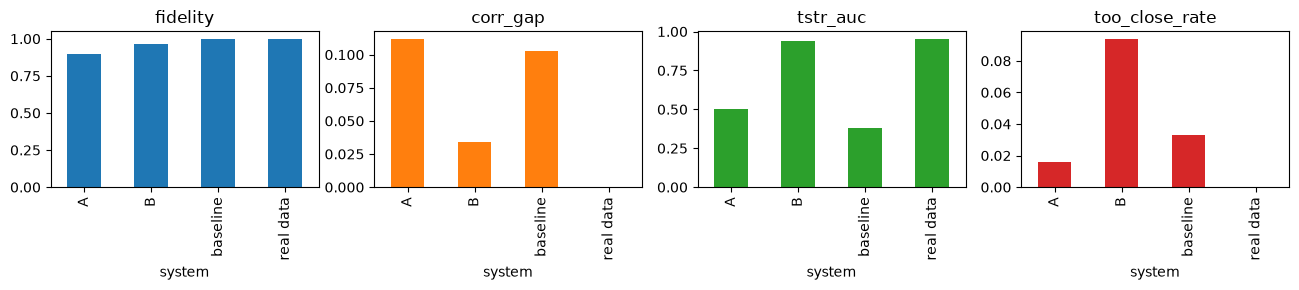

In [11]:
summary.loc[["A", "B", "baseline", "real data"]].plot(kind="bar", subplots=True, layout=(1, 4),
                                                         figsize=(13, 3), legend=False)
plt.tight_layout()
plt.savefig("results/p1/metrics.png")